In [15]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sps

import jlinops

Want a grad operator that acts on $N_x \times N_y \times N_t$ images...

In [3]:
Nx = 5
Ny = 5
Nt = 3

np.random.seed(0)
vox = np.random.normal(size=(Nx, Ny, Nt))

In [10]:
L2d = jlinops.Neumann2D((Nx, Ny))
L2dmat = jlinops.black_box_to_dense(L2d)

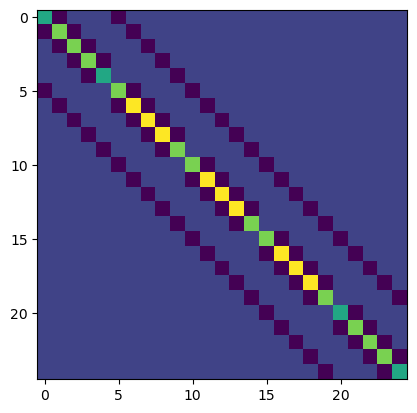

In [12]:
plt.imshow(L2dmat.T @ L2dmat)

In [9]:
L2d

<50x25 Neumann2D with dtype=float64>

In [14]:
Nx*Ny*Nt

75

In [17]:
L2dmat = jlinops.build_neumann2d_sparse_matrix((Nx, Ny))

In [19]:
sps.kron(L2dmat, sps.eye(Nt))

<150x75 sparse matrix of type '<class 'numpy.float64'>'
	with 240 stored elements in COOrdinate format>

In [21]:
jlinops.first_order_derivative_1d(3, boundary="reflexive")[0].toarray()

array([[ 1., -1.,  0.],
       [ 0.,  1., -1.],
       [ 0.,  0.,  0.]])

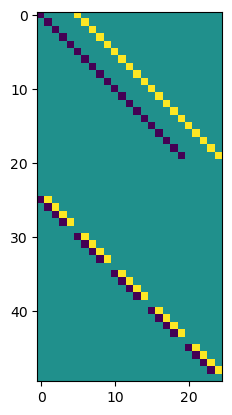

In [23]:
plt.imshow(L2dmat.toarray())

# What I think we need?

Underneath, just stack result of matvec with this matrix? 
$$
L_t = \begin{bmatrix}
I & -I & & \\ & \ddots & \ddots & \\
& & I & -I \\ 
& & & & 
\end{bmatrix}, \quad L_t^T = \begin{bmatrix} I & & & \\ 
-I & \ddots & & \\
& \ddots & I & \\
& & -I & 
\end{bmatrix}
$$

In [28]:
from jlinops import _CustomLinearOperator
import math

In [24]:
vox = np.random.normal(size=(Nx, Ny, Nt))

In [383]:
class Voxel2DTemporalGrad(_CustomLinearOperator):
    """Given a stack of Nt images of shape (Nx,Ny), so the input vector x is the result of 
    .flatten() applied to a (Nx,Ny,Nt) array, returns the flattened voxel gradient in the temporal direction.
    """
    def __init__(self, voxel_shape, device="cpu"):
        

        self.Nx, self.Ny, self.Nt = voxel_shape # unpack shapes
        self.voxel_shape = voxel_shape
        n = math.prod(self.voxel_shape)
        shape = (n,n)
        #shape = ?
        

        def _matvec(x):
            x = x.reshape(self.voxel_shape) # reshape it
            result = np.zeros(self.voxel_shape)
            for j in range(self.Nt-1): # we skipped the last slice, since this should be zero...
                result[:,:,j] = x[:,:,j] - x[:,:,j+1]
            return result.flatten()


        def _rmatvec(x):
            x = x.reshape(self.voxel_shape)
            result = np.zeros(self.voxel_shape)
            result[:,:,0] = x[:,:,0]
            for j in range(1,self.Nt-1):
                result[:,:,j] = x[:,:,j] - x[:,:,j-1]
            result[:,:,-1] = -x[:,:,-2]
            return result.flatten()


        # if device == "cpu":
            
        #     def _matvec(x):
        #         return sp_dctn( x.reshape(self.grid_shape), norm="ortho", type=self.type ).flatten()
            
        #     def _rmatvec(x):
        #         return sp_idctn( x.reshape(self.grid_shape), norm="ortho", type=self.type ).flatten()
            
        # else:
            
        #     def _matvec(x):
        #         return cp_dctn( x.reshape(self.grid_shape), norm="ortho", type=self.type ).flatten()
            
        #     def _rmatvec(x):
        #         return cp_idctn( x.reshape(self.grid_shape), norm="ortho", type=self.type ).flatten()
              
        super().__init__(shape, _matvec, _rmatvec, device=device)
        
    
    # def to_gpu(self):
    #     return DCT2D(self.grid_shape, device="gpu", type=self.type)
    
    # def to_cpu(self):
    #     return DCT2D(self.grid_shape, device="cpu", type=self.type)


In [384]:
Lt = Voxel2DTemporalGrad((Nx, Ny, Nt))

In [386]:
Lt.T @ (Lt @ np.random.normal(size=Lt.shape[1]))

array([-2.93508669,  2.33741256,  0.59767413, -0.98689052,  2.89167485,
       -1.90478432,  3.34306763, -6.51820487,  3.17513724, -0.44315082,
        2.00574743, -1.56259662, -0.14192964,  0.84695318, -0.70502353,
        1.99714284, -3.02623798,  1.02909515,  0.59190982, -2.55306741,
        1.96115759,  0.33049355,  0.59702503, -0.92751858, -2.11240385,
        3.89507961, -1.78267576,  1.99350903, -2.82491936,  0.83141034,
       -1.91484461,  2.67377961, -0.758935  , -0.56113019,  1.22296348,
       -0.66183329, -1.67975247,  0.85983748,  0.819915  ,  0.92317804,
       -1.65142146,  0.72824343, -1.48250867,  1.21258218,  0.26992649,
        2.78286856, -4.34693039,  1.56406183,  0.7494666 ,  0.47059301,
       -1.22005961,  0.4889418 , -0.68157136,  0.19262956,  0.61189145,
        1.85002942, -2.46192087,  1.03998248, -1.22098822,  0.18100574,
       -0.30538139,  0.93568243, -0.63030104, -0.58154083,  0.1512452 ,
        0.43029563, -0.87019122,  0.32579622,  0.544395  ,  1.08

In [387]:
Ltmat = jlinops.black_box_to_dense(Lt)


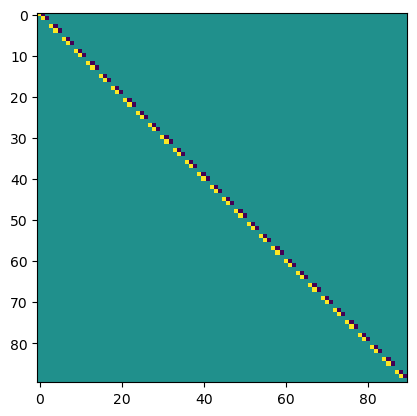

In [388]:
plt.imshow(Ltmat)
plt.show()

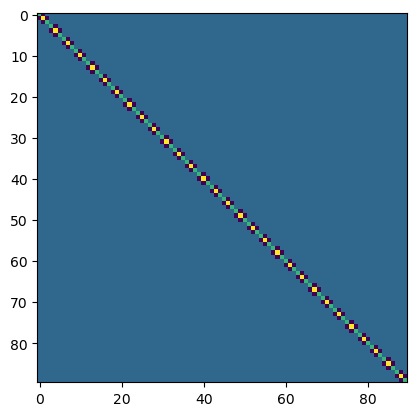

In [389]:
plt.imshow(Ltmat.T @ Ltmat)
plt.show()

In [390]:
(vox[:,:,1] - vox[:,:,0]).shape

(5, 5)

# Also make voxel 2D Neumann?

This just diagonally stacks copies of Neumann2D... transpose also is just stacked copies of the transpose...

In [ ]:
class VoxelNeumann2DSpatial(_CustomLinearOperator):
    """Given a stack of Nt images of shape (Nx,Ny), so the input vector x is the result of 
    .flatten() applied to a (Nx,Ny,Nt) array, returns the flattened voxel gradient in the spatial directions (stacked on top of each other)
    """
    def __init__(self, voxel_shape, device="cpu"):
        

        Nx, Ny, Nt = voxel_shape # unpack shapes
        self.voxel_shape = voxel_shape
        n = math.prod(self.voxel_shape)
        shape = (n,n)
        self.Lspatial = jlinops.Neumann2D((self.Nx, self.Ny))
        shape = ( self.Lspatial.shape[0]*self.Nt, n)    

        def _matvec(x):
            x = x.reshape(self.voxel_shape) # reshape it
            result = np.zeros((2*self.Nx*self.Ny, self.Nt))
            for j in range(self.Nt):
                result[:,j] = self.Lspatial @ x[:,:,j].flatten() 
            return result.flatten()


        def _rmatvec(x):
            result = []
            result = np.zeros((self.Nx, self.Ny, self.Nt))
            tmp = x.reshape((2*self.Nx*self.Ny, self.Nt))
            for j in range(self.Nt):
                result[:,:,j] = (self.Lspatial.T @ tmp[:,j]).reshape((self.Nx, self.Ny))

            return result.flatten()


        super().__init__(shape, _matvec, _rmatvec, device=device)
        
    
    # def to_gpu(self):
    #     return DCT2D(self.grid_shape, device="gpu", type=self.type)
    
    # def to_cpu(self):
    #     return DCT2D(self.grid_shape, device="cpu", type=self.type)


In [392]:
Ls = VoxelNeumann2DSpatial((Nx, Ny, Nt))

In [393]:
5*5*5

125

In [394]:
2*6*5*3

180

In [395]:
Ls @ np.zeros(Ls.shape[1])

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [396]:
Ls @ np.random.normal(size=Ls.shape[1])

array([ 1.68326215,  1.92656859,  3.12701724, -0.47770806,  2.02570768,
       -0.61101619, -0.44292809,  0.53961908, -0.17418501,  0.43284761,
       -0.39734119,  0.36262127, -1.40323895,  0.65346091, -2.22849582,
       -0.11763619, -0.99856543, -1.02334936, -0.8826234 ,  0.71888862,
        1.41345971,  1.47944708, -1.86688431, -0.47761933, -1.67587185,
        1.31725144,  1.6087442 ,  0.71519379, -0.0726675 ,  0.54821269,
       -1.15199631,  0.42798889, -1.38652486,  1.44599765, -2.52055066,
       -0.79321517, -0.98634322,  0.99168494, -0.69539882,  2.18297712,
       -3.47092382, -1.63676792,  3.9928382 , -0.18471618,  1.65217941,
        0.77458621, -1.50895507,  0.92920558, -0.20435571,  0.5113796 ,
       -2.77155159,  1.1861808 ,  0.31005298,  0.36732438, -1.30147144,
        2.58394528,  1.36870792, -2.47220637,  0.84895688, -1.81021891,
       -0.38117531,  1.34699973, -1.16041954, -1.42533888,  0.84498251,
        3.45605685, -1.14201223,  0.54072333,  1.51942487,  1.38

In [397]:
Ls.T.shape[1]

180

In [398]:
Ls.shape[0]

180

In [399]:
Ls.T @ np.zeros(Ls.shape[0])

array([-0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0., -0.,
       -0., -0., -0., -0., -0., -0., -0., -0., -0.,  0.,  0.,  0.])

In [400]:
# Ls.T @ (Ls @ vox.flatten() )

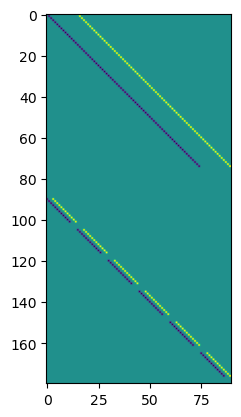

In [401]:
plt.imshow(jlinops.black_box_to_dense(Ls))
plt.show()

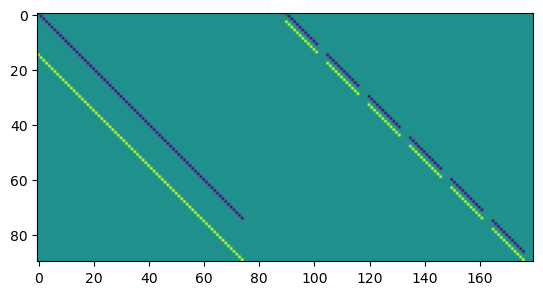

In [402]:
plt.imshow(jlinops.black_box_to_dense(Ls).T)
plt.show()

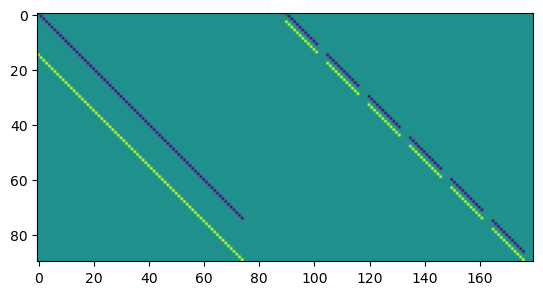

In [403]:
plt.imshow(jlinops.black_box_to_dense(Ls.T))
plt.show()

In [404]:
jlinops.check_adjoint(Ls)

True

# Don't quite have the transpose correct... anyways, just try stacking in matrix form and see if diagonalized by DCT?

In [538]:
Nx = 6
Ny = 5
Nt = 3

In [539]:
Lt = Voxel2DTemporalGrad((Nx, Ny, Nt))
Ls = VoxelNeumann2DSpatial((Nx, Ny, Nt))
Lsmat = jlinops.black_box_to_dense(Ls)
Ltmat = jlinops.black_box_to_dense(Lt)

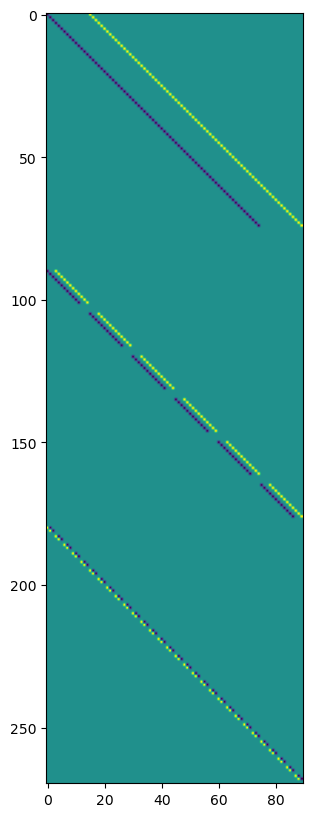

In [540]:
plt.figure(figsize=(5,10))
plt.imshow(np.vstack([Lsmat, Ltmat]))
plt.show()

In [541]:
Smat = np.vstack([Lsmat, Ltmat])
M = Smat.T @ Smat

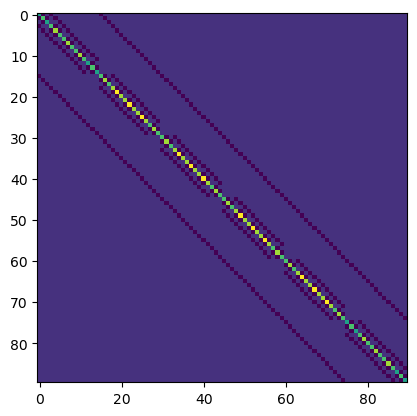

In [542]:
plt.imshow(M)
plt.show()

In [543]:
Smat = np.vstack([Lsmat, Ltmat])
M = Smat.T @ Smat

In [544]:
eigM = np.linalg.eig(M)

In [545]:
from scipy.fft import idctn, dctn

In [546]:
v1 = np.random.normal(size=(Nx,Ny,Nt)) + 13.0
#v = np.ones((Nx,Ny,Nt))
tmp1 = M @ (idctn( v1, norm="ortho", type=2 ).flatten() )
tmp1 = tmp1.reshape((Nx, Ny, Nt))
tmp1 = dctn( tmp1, norm="ortho", type=2 ).flatten()
res1 = tmp1/v1.flatten()


In [547]:
v2 = np.random.normal(size=(Nx,Ny,Nt)) + 25.0
#v = np.ones((Nx,Ny,Nt))
tmp2 = M @ (idctn( v2, norm="ortho", type=2 ).flatten() )
tmp2 = tmp2.reshape((Nx, Ny, Nt))
tmp2 = dctn( tmp2, norm="ortho", type=2 ).flatten()
res2 = tmp2/v2.flatten()


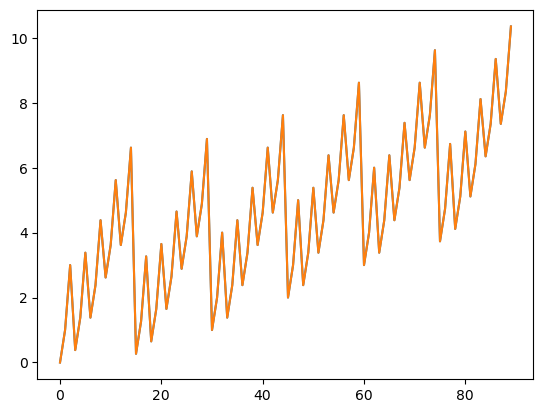

In [548]:
plt.plot(res1)
plt.plot(res2)

In [549]:
np.linalg.norm(res1 - res2)

1.782458571525856e-14

# Seems to work! Let's make some more operators

In [550]:
Nx = 6
Ny = 6
Nt = 3
voxel_shape = (6,5,3)

In [551]:
def build_spatiotemporal_neumann2d(voxel_shape):
    """Builds the spatio-temporal . 
    voxel shape should be (Nx, Ny, Nt).
    """
    Nx, Ny, Nt = voxel_shape

    Ls = VoxelNeumann2DSpatial((Nx, Ny, Nt))
    Lt = Voxel2DTemporalGrad((Nx, Ny, Nt))
    L = jlinops.StackedOperator([Ls, Lt])

    return L

In [552]:
L = build_spatiotemporal_neumann2d(voxel_shape)

In [553]:
jlinops.check_adjoint(L)

True

In [554]:
Lmat =  jlinops.black_box_to_dense(L)

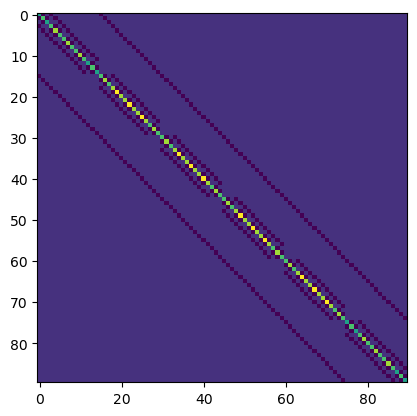

In [555]:
plt.imshow(Lmat.T @ Lmat)

In [556]:
from scipy.fft import dctn as sp_dctn
from scipy.fft import idctn as sp_idctn

In [557]:
# Operator for 3D DCT

class DCT3D(_CustomLinearOperator):
    """Represents a 3-dimensional DCT transform.
    Convention is (Nx, Ny, Nt).
    """
    def __init__(self, voxel_shape, device="cpu", type=2):
        
        # Handle shape
        self.voxel_shape = voxel_shape
        n = math.prod(self.voxel_shape)
        self.type = type
        shape = (n,n)
        
        if device == "cpu":
            
            def _matvec(x):
                return sp_dctn( x.reshape(self.voxel_shape), norm="ortho", type=self.type ).flatten()
            
            def _rmatvec(x):
                return sp_idctn( x.reshape(self.voxel_shape), norm="ortho", type=self.type ).flatten()
            
        else:
            
            def _matvec(x):
                return cp_dctn( x.reshape(self.voxel_shape), norm="ortho", type=self.type ).flatten()
            
            def _rmatvec(x):
                return cp_idctn( x.reshape(self.voxel_shape), norm="ortho", type=self.type ).flatten()
              
        super().__init__(shape, _matvec, _rmatvec, device=device)
        
    
    def to_gpu(self):
        return DCT3D(self.voxel_shape, device="gpu", type=self.type)
    
    def to_cpu(self):
        return DCT3D(self.voxel_shape, device="cpu", type=self.type)


In [558]:
# Operator for the pseudoinverse of L.T L
Z = DCT3D(voxel_shape)

In [ ]:
def dct3d_get_eigvals(A, voxel_shape, make_pos=False, type=2):
    """Given an SSPD LinearOperator A that is diagonalized by the 3-dimensional DCT, computes its eigenvalues.
    """
    # Shape of dct
    Nx, Ny, Nt = voxel_shape
    
    device = A.device
    if device == "cpu":
        v = np.random.normal(size=voxel_shape) + 10.0
        #v = np.ones(voxel_shape)
        tmp = A @ ( sp_idctn( v, norm="ortho", type=type ).flatten()  )
        tmp = tmp.reshape(voxel_shape)
        tmp = sp_dctn( tmp, norm="ortho", type=type ).flatten()
        res = tmp/v.flatten()
        if make_pos:
            res = np.abs(res)
        return res
    else:
        v = cp.random.normal(size=voxel_shape) + 10.0
        #v = cp.ones(voxel_shape)
        tmp = A @ ( cp_idctn( v, norm="ortho", type=type ).flatten()  )
        tmp = tmp.reshape(voxel_shape)
        tmp = cp_dctn( tmp, norm="ortho", type=type ).flatten()
        res = tmp/v.flatten()
        if make_pos:
            res = cp.abs(res)
        return res


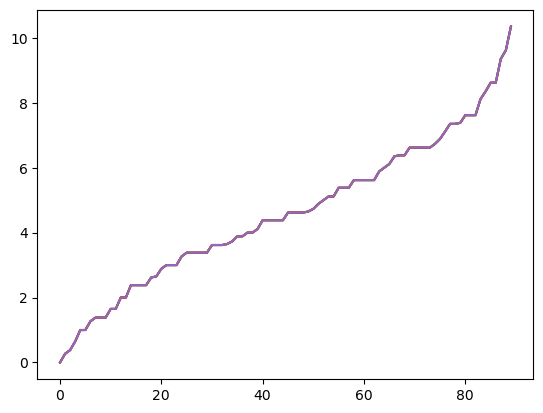

In [560]:
for j in range(5):
    plt.plot(np.sort(dct3d_get_eigvals(L.T @ L, voxel_shape)))

In [561]:
v1 = dct3d_get_eigvals(L.T @ L, voxel_shape)
v2 = dct3d_get_eigvals(L.T @ L, voxel_shape)
np.linalg.norm(v1 - v2)

2.1147433631741085e-14

In [ ]:
def dct3d_pinv(A, voxel_shape, eps=1e-14, type=2):
    """Given a LinearOperator A that is diagonalized by the DCT3D, performs the diagonalization (computes eigenvalues), returns a LinearOperator representing A^\dagger (pseudoinverse).
    """
    # Get eigenvalues
    eigvals = dct3d_get_eigvals(A, voxel_shape, type=type)
    device = jlinops.get_device(eigvals)

    # Take reciprocals of nonzero eigenvalues
    if device == "cpu":
        recip_eigvals = np.where( np.abs(eigvals) < eps, eigvals, 1.0 / np.clip(eigvals, a_min=eps, a_max=None) )
        recip_eigvals = np.where( np.abs(eigvals) < eps, np.zeros_like(eigvals), recip_eigvals )
    else:
        recip_eigvals = cp.where( cp.abs(eigvals) < eps, eigvals, 1.0 / cp.clip(eigvals, a_min=eps, a_max=None) )
        recip_eigvals = cp.where( cp.abs(eigvals) < eps, cp.zeros_like(eigvals), recip_eigvals )
    
    # DCT op
    P = DCT3D(voxel_shape, device=device, type=type)
    
    # Apinv op
    Apinv = P.T @ ( jlinops.DiagonalOperator(recip_eigvals) @ P)
    
    return Apinv


In [571]:
Mpinv = dct3d_pinv(L.T @ L, voxel_shape)

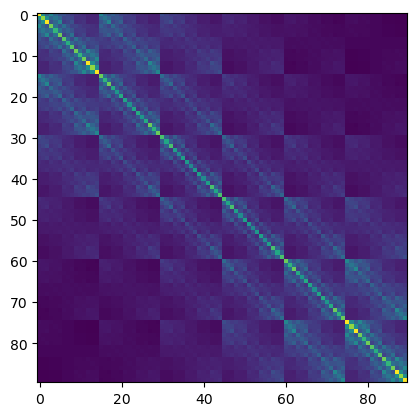

In [573]:
plt.imshow( jlinops.black_box_to_dense(Mpinv) )
plt.show()

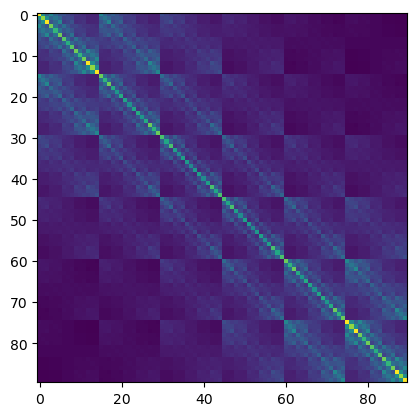

In [575]:
plt.imshow(np.linalg.pinv(M))
plt.show()

In [577]:
from scipy.linalg import null_space

In [578]:
null_space(M)

array([[0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.10540926],
       [0.105

# Preconditioned weighted pseudoinverse?

In [ ]:

class CGWeightedVoxelGradPinvCPUOperator(_CustomLinearOperator):
    """
    """

    def __init__(self, voxel_shape, weights, warmstart_prev=False, check=False, which="scipy", dct_eps=1e-14, *args, **kwargs):

        self.weights = weights
        self.voxel_shape = voxel_shape
        self.warmstart_prev = warmstart_prev
        self.check = check
        self.which = which
        self.dct_eps = dct_eps
        self.args = args
        self.kwargs = kwargs
        
        # Figure out device
        device = jlinops.get_device(weights)

        # Build R and R_w
        self.R = build_spatiotemporal_neumann2d(self.voxel_shape)
        assert self.R.shape[0] == len(weights), "Weights incompatible!"
        self.RtR = self.R.T @ self.R
        self.Dw = jlinops.DiagonalOperator(weights)
        self.Rw = self.Dw @ self.R

        # Get Rpinv (with identity weights)
        self.RtRpinv = dct3d_pinv( self.RtR, self.voxel_shape, eps=dct_eps )

        # Take care of W (columns span the kernel of R)
        if device == "cpu":
            W = np.ones((self.R.shape[1],1))
        else:
            W = cp.ones((self.R.shape[1],1))
            
        self.W = jlinops.MatrixLinearOperator(W)
        self.Wpinv = jlinops.QRPinvOperator(self.W)

        # Make Rwpinv
        self.Rwpinv = jlinops.CGPreconditionedPinvModOperator(self.Rw, self.W, self.Wpinv, self.RtRpinv, warmstart_prev=warmstart_prev, check=check, which=which, *args, **kwargs)

        def _matvec(x):
            return self.Rwpinv.matvec( x )

        def _rmatvec(x):
            return  self.Rwpinv.rmatvec( x ) 

        # def _matvec(x):
        #     return cp.asnumpy( self.Rwpinv.matvec( cp.asarray(x) ) )

        # def _rmatvec(x):
        #     return cp.asnumpy( self.Rwpinv.rmatvec( cp.asarray(x) ) )

        super().__init__( self.Rwpinv.shape, _matvec, _rmatvec, dtype=np.float64, device=device)
        

    def to_gpu(self):
        raise NotImplementedError
        #return CGWeightedNeumann2DPinvOperator(self.grid_shape, cp.asarray(self.weights), warmstart_prev=self.warmstart_prev, check=self.check, which=self.which, dct_eps=self.dct_eps, *self.args, **self.kwargs)
    
    def to_cpu(self):
        raise NotImplementedError
        #return CGWeightedNeumann2DPinvOperator(self.grid_shape, cp.numpy(self.weights), warmstart_prev=self.warmstart_prev, check=self.check, which=self.which, dct_eps=self.dct_eps, *self.args, **self.kwargs)
    



In [ ]:

class CGWeightedVoxelGradPinvGPUOperator(_CustomLinearOperator):
    """
    """

    def __init__(self, voxel_shape, weights, warmstart_prev=False, check=False, which="scipy", dct_eps=1e-14, *args, **kwargs):

        self.weights = weights
        self.voxel_shape = voxel_shape
        self.warmstart_prev = warmstart_prev
        self.check = check
        self.which = which
        self.dct_eps = dct_eps
        self.args = args
        self.kwargs = kwargs
        
        # Figure out device
        device = jlinops.get_device(weights)

        # Build R and R_w
        self.R = build_spatiotemporal_neumann2d(self.voxel_shape)
        assert self.R.shape[0] == len(weights), "Weights incompatible!"
        self.RtR = self.R.T @ self.R
        self.Dw = jlinops.DiagonalOperator(weights)
        self.Rw = self.Dw @ self.R

        # Get Rpinv (with identity weights)
        self.RtRpinv = dct3d_pinv( self.RtR, self.voxel_shape, eps=dct_eps )

        # Take care of W (columns span the kernel of R)
        if device == "cpu":
            W = np.ones((self.R.shape[1],1))
        else:
            W = cp.ones((self.R.shape[1],1))
            
        self.W = jlinops.MatrixLinearOperator(W)
        self.Wpinv = jlinops.QRPinvOperator(self.W)

        # Make Rwpinv
        self.Rwpinv = jlinops.CGPreconditionedPinvModOperator(self.Rw, self.W, self.Wpinv, self.RtRpinv, warmstart_prev=warmstart_prev, check=check, which=which, *args, **kwargs).to_gpu()

        def _matvec(x):
            return cp.asnumpy( self.Rwpinv.matvec( cp.asarray(x) ) )

        def _rmatvec(x):
            return cp.asnumpy( self.Rwpinv.rmatvec( cp.asarray(x) ) )

        super().__init__( self.Rwpinv.shape, _matvec, _rmatvec, dtype=np.float64, device=device)
        

    def to_gpu(self):
        raise NotImplementedError
        #return CGWeightedNeumann2DPinvOperator(self.grid_shape, cp.asarray(self.weights), warmstart_prev=self.warmstart_prev, check=self.check, which=self.which, dct_eps=self.dct_eps, *self.args, **self.kwargs)
    
    def to_cpu(self):
        raise NotImplementedError
        #return CGWeightedNeumann2DPinvOperator(self.grid_shape, cp.numpy(self.weights), warmstart_prev=self.warmstart_prev, check=self.check, which=self.which, dct_eps=self.dct_eps, *self.args, **self.kwargs)
    



In [589]:
Nx = 5
Ny = 6
Nt = 5
L = build_spatiotemporal_neumann2d(voxel_shape)
weights = np.random.uniform(low=1, high=5, size=L.shape[0])

In [594]:
WL = jlinops.DiagonalOperator(weights) @ L

In [596]:
WLmat = jlinops.black_box_to_dense(WL)

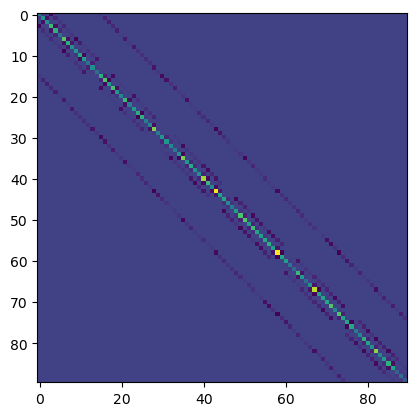

In [597]:
plt.imshow(WLmat.T @ WLmat)

In [ ]:
np.linalg.pinv(WLmat)

array([[-1.71787681,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        , -3.46183131,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        , -3.74774256, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  1.93312514,
        -1.93312514,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         1.85092216, -1.85092216],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]])

In [605]:
n_tries = 50
WLpinvmat = np.linalg.pinv(WLmat)
WLpinv = CGWeightedVoxelGradPinvOperator(voxel_shape, weights, tol=1e-8)
errs = []
for j in range(n_tries):
    u1 = np.random.normal(size=WL.shape[0])
    v1 = WLpinvmat @ u1
    v2 = WLpinv @ u1
    err = np.linalg.norm(v1 - v2)
    errs.append(err)

In [606]:
errs

[2.510708342109104e-08,
 2.3042767325232182e-08,
 8.354437480357905e-09,
 2.6394136486931235e-08,
 1.3649051284565986e-08,
 1.0862340876679386e-08,
 1.0796691165516073e-08,
 2.2275251620073864e-08,
 8.539664754838721e-09,
 1.1282126702539496e-08,
 1.1446234920616616e-08,
 2.6276669112101017e-08,
 1.0812275857185495e-08,
 1.0517053348966556e-08,
 1.0281447286675156e-08,
 1.394643892076733e-08,
 1.8895378185444307e-08,
 9.018411893467231e-09,
 1.0437742857058275e-08,
 9.207117390495447e-09,
 2.3377680558014953e-08,
 1.1453544381244399e-08,
 2.8897913225983454e-08,
 2.732733395192821e-08,
 2.38763831564921e-08,
 2.022471685071426e-08,
 1.0841968643942213e-08,
 1.0044616864990932e-08,
 3.79883398767773e-08,
 1.2934497355216963e-08,
 1.1957369015789536e-08,
 2.731772606193379e-08,
 2.6885600889109737e-08,
 1.1548858385766213e-08,
 2.526902764578302e-08,
 2.6877136692631004e-08,
 3.3618889645761547e-08,
 2.6782506804859147e-08,
 1.0116434147549308e-08,
 1.1017989695292459e-08,
 8.91815372953

In [ ]:
v = np.random.normal(eig) + 10.0
v = np.ones((M,N))
tmp = A @ ( sp_idctn( v, norm="ortho", type=type ).flatten()  )
tmp = tmp.reshape((M,N))
tmp = sp_dctn( tmp, norm="ortho", type=type ).flatten()
res = tmp/v.flatten()

In [ ]:
if device == "cpu":
        v = np.random.normal(size=(M,N)) + 10.0
        v = np.ones((M,N))
        tmp = A @ ( sp_idctn( v, norm="ortho", type=type ).flatten()  )
        tmp = tmp.reshape((M,N))
        tmp = sp_dctn( tmp, norm="ortho", type=type ).flatten()
        res = tmp/v.flatten()
        if make_pos:
            res = np.abs(res)
        return res

In [ ]:
# class Neumann2DPinvOperator(_CustomLinearOperator):
#     """Represents the pseudoinverse R^\dagger where R is a Neumann2D operator.
#     Here matvecs/rmatvecs are applied using a DCT transform method. 
#     """
    
#     def __init__(self, grid_shape, device="cpu", eps=1e-14):
        
#         # Grid shape
#         self.grid_shape = grid_shape
#         self.eps = eps
        
#         # Neumann2D operator
#         self.R = Neumann2D(grid_shape, device=device)
#         self.Apinv = dct_pinv(self.R.T @ self.R, grid_shape, eps=self.eps)
        
#         def _matvec(x):
#             return self.Apinv.matvec(x)

#         def _rmatvec(x):
#             return self.Apinv.rmatvec(x)
        
#         super().__init__( self.Apinv.shape, _matvec, _rmatvec, dtype=np.float64, device=device)
        
#     def to_gpu(self):
#         return Neumann2DPinvOperator(self.grid_shape, device="gpu", eps=self.eps)
    
#     def to_cpu(self):
#         return Neumann2DPinvOperator(self.grid_shape, device="cpu", eps=self.eps)

    


# def dct_pinv(A, grid_shape, eps=1e-14, type=2):
#     """Given a LinearOperator A that is diagonalized by the DCT, performs the diagonalization (computes eigenvalues), returns a LinearOperator representing A^\dagger (pseudoinverse).
#     """
#     # Get eigenvalues
#     eigvals = dct_get_eigvals(A, grid_shape, type=type)
#     device = get_device(eigvals)

#     # Take reciprocals of nonzero eigenvalues
#     if device == "cpu":
#         recip_eigvals = np.where( np.abs(eigvals) < eps, eigvals, 1.0 / np.clip(eigvals, a_min=eps, a_max=None) )
#         recip_eigvals = np.where( np.abs(eigvals) < eps, np.zeros_like(eigvals), recip_eigvals )
#     else:
#         recip_eigvals = cp.where( cp.abs(eigvals) < eps, eigvals, 1.0 / cp.clip(eigvals, a_min=eps, a_max=None) )
#         recip_eigvals = cp.where( cp.abs(eigvals) < eps, cp.zeros_like(eigvals), recip_eigvals )
    
#     # DCT op
#     P = DCT2D(grid_shape, device=device, type=type)
    
#     # Apinv op
#     Apinv = P.T @ ( DiagonalOperator(recip_eigvals) @ P)
    
#     return Apinv
